# TRABAJO FIN DE GRADO: Detección de TEA mediante sistemas de IA

#### **Estudiante**: Ángel Vilariño García
#### **Dirección**: Verónica Bolón Canedo y Brais Cancela Barizo

---
## Capítulo 5 · Sección Final: Optimización de hiperparámetros y evaluación del modelo ganador


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import json
import pyreadstat
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    roc_curve, auc, ConfusionMatrixDisplay, classification_report,
    precision_recall_curve, average_precision_score
)
from sklearn.model_selection import cross_validate
from IPython.display import display
from pathlib import Path

DIR_GRAFICAS = Path('graficas_cap5')
DIR_GRAFICAS.mkdir(exist_ok=True)

def guardar_grafica(nombre_archivo, fig=None, dpi=300):
    if fig is None:
        fig = plt.gcf()
    ruta = DIR_GRAFICAS / nombre_archivo
    fig.savefig(ruta, dpi=dpi, bbox_inches='tight')

# Paleta consistente para todos los modelos
PALETTE = {
    'MLP':               '#1f77b4',
    'SVM':               '#ff7f0e',
    'LogisticRegression':'#2ca02c',
    'RandomForest':      '#d62728',
    'GradientBoosting':  '#9467bd'
}

# ── Carga de datos y preprocesamiento ──────────────────────────────────────────
with open('resultados/mejores_variables.json', 'r') as f:
    features_finales = json.load(f)

df, meta = pyreadstat.read_sav('TEA_1.sav')

X_opt = df[features_finales]
y_opt = df['Diag_primario']

# KNN imputation + estandarización (coherente con el pipeline de experimentación)
X_proc = StandardScaler().fit_transform(
    KNNImputer(n_neighbors=5).fit_transform(X_opt)
)

# Validación cruzada estratificada 5-fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

METRICAS_DICT = {
    'accuracy':  'accuracy',
    'precision': 'precision',
    'recall':    'recall',
    'f1':        'f1',
    'roc_auc':   'roc_auc'
}
METRICAS = list(METRICAS_DICT.keys())

print(f"Configuración lista: {X_proc.shape[0]} sujetos · {X_proc.shape[1]} variables.")

Configuración lista: 209 sujetos · 20 variables.


---
### 1. Búsqueda de hiperparámetros: GridSearchCV

In [29]:
# PARRILLAS DE HIPERPARÁMETROS

param_grids = {
    'SVM': {
        'model': SVC(random_state=42, probability=True),
        'params': {
            'C':      [0.1, 1, 10, 100],
            'gamma':  ['scale', 'auto', 0.01, 0.1],
            'kernel': ['rbf', 'linear']
        }
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators':    [100, 300, 500],
            'max_depth':       [None, 10, 20],
            'min_samples_leaf':[1, 2, 4]
        }
    },
    'MLP': {
        'model': MLPClassifier(random_state=42, max_iter=1000),
        'params': {
            'hidden_layer_sizes': [(50,), (100,), (100, 50)],
            'activation':         ['relu', 'tanh'],
            'alpha':              [0.0001, 0.001, 0.01],
            'learning_rate_init': [0.001, 0.01]
        }
    },
    'LogisticRegression': {
        'model': LogisticRegression(random_state=42, max_iter=1000),
        'params': {
            'C':       [0.01, 0.1, 1, 10, 100],
            'penalty': ['l1', 'l2'],
            'solver':  ['liblinear', 'saga']
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'n_estimators':  [100, 300, 500],
            'learning_rate': [0.01, 0.1, 0.2],
            'max_depth':     [3, 5, 7],
        }
    }
}

resultados_grid = []

for nombre, config in param_grids.items():
    print(f"Ejecutando GridSearch para {nombre}...")
    grid = GridSearchCV(
        config['model'],
        config['params'],
        cv=skf,
        scoring=METRICAS_DICT,
        refit='f1',
        n_jobs=-1,
        return_train_score=False
    )
    grid.fit(X_proc, y_opt)

    df_res = pd.DataFrame(grid.cv_results_)
    df_res['Algoritmo'] = nombre
    resultados_grid.append(df_res)

df_grid = pd.concat(resultados_grid, ignore_index=True)
df_grid.to_csv('resultados/optimizacion_gridsearch.csv', index=False)
print("\nGridSearch finalizado y resultados guardados.")

Ejecutando GridSearch para SVM...
Ejecutando GridSearch para RandomForest...
Ejecutando GridSearch para MLP...
Ejecutando GridSearch para LogisticRegression...
Ejecutando GridSearch para GradientBoosting...


/Users/mangelvilarino/opt/anaconda3/envs/aa2/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mangelvilarino/opt/anaconda3/envs/aa2/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mangelvilarino/opt/anaconda3/envs/aa2/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me


GridSearch finalizado y resultados guardados.


---
### 2. Mejor configuración por modelo

In [30]:
# ANÁLISIS 1: RANKING MAESTRO Y CONFIGURACIÓN ÓPTIMA

# 1. Cargar resultados
df_grid = pd.read_csv('resultados/optimizacion_gridsearch.csv')

metricas = ['f1', 'recall', 'precision', 'accuracy', 'roc_auc']
cols_rename = {f'mean_test_{m}': m for m in metricas}

# 2. PROCESAR GRIDSEARCH (SVM, RF, MLP, LR, GB)
# Buscamos el mejor por algoritmo y extraemos los parámetros
ranking_grid = df_grid.sort_values('mean_test_f1', ascending=False).drop_duplicates('Algoritmo').copy()

# Los parámetros en GridSearch están en columnas que empiezan por 'param_'
cols_params_grid = [c for c in df_grid.columns if c.startswith('param_')]
ranking_grid['Configuración'] = ranking_grid[cols_params_grid].apply(
    lambda x: ', '.join([f"{k.replace('param_', '')}: {v}" for k, v in x.items() if pd.notnull(v)]), axis=1
)

ranking_grid = ranking_grid.rename(columns=cols_rename)[['Algoritmo'] + metricas + ['Configuración']]

# 3. MOSTRAR RANKING FINAL
df_final = ranking_grid.sort_values('f1', ascending=False).reset_index(drop=True)

print(" RANKING FINAL Y MEJORES CONFIGURACIONES (TOP-20 VARIABLES)")
# Mostramos la tabla con degradado en métricas y texto plano para la configuración
display(df_final.style.background_gradient(cmap='YlGnBu', subset=metricas)\
               .format({m: "{:.4f}" for m in metricas})\
               .set_properties(subset=['Configuración'], **{'text-align': 'left', 'font-size': '10px'}))

 RANKING FINAL Y MEJORES CONFIGURACIONES (TOP-20 VARIABLES)


,Algoritmo,f1,recall,precision,accuracy,roc_auc,Configuración
0,MLP,0.8726,0.8674,0.8895,0.8805,0.9204,"activation: tanh, alpha: 0.0001, hidden_layer_sizes: (50,), learning_rate_init: 0.001"
1,LogisticRegression,0.8640,0.8779,0.8585,0.8708,0.9282,"C: 1.0, penalty: l1, solver: liblinear"
2,SVM,0.8481,0.8568,0.8449,0.8564,0.9204,"C: 1.0, gamma: 0.01, kernel: linear"
3,RandomForest,0.8163,0.8068,0.8360,0.8325,0.8982,"min_samples_leaf: 2.0, n_estimators: 300.0"
4,GradientBoosting,0.8106,0.7968,0.8457,0.8276,0.9030,"max_depth: 5.0, n_estimators: 300.0, learning_rate: 0.1"


---
### 3. Comparativa global de modelos optimizados

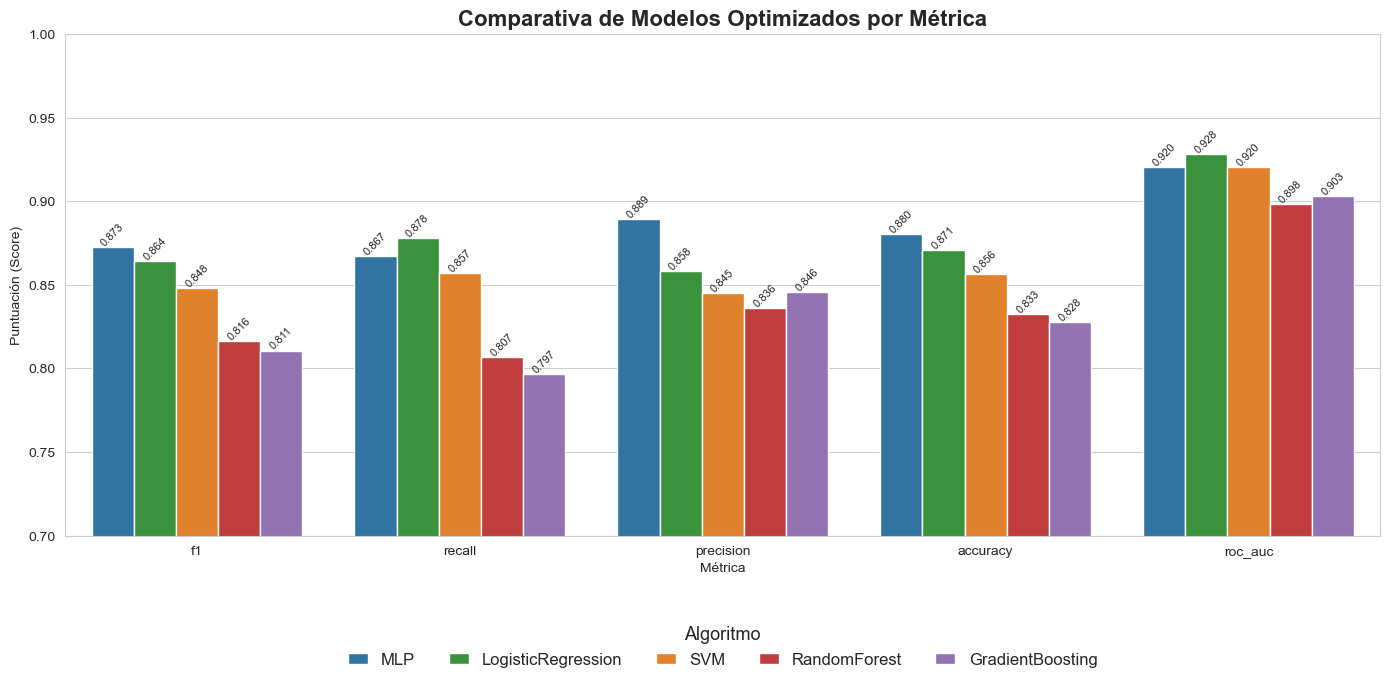

In [31]:
palette_modelos = {
    'MLP': '#1f77b4',
    'SVM': '#ff7f0e',
    'LogisticRegression': '#2ca02c',
    'RandomForest': '#d62728',
    'GradientBoosting': '#9467bd'
}

df_plot = df_final.melt(id_vars='Algoritmo', value_vars=metricas, var_name='Métrica', value_name='Valor')

plt.figure(figsize=(14, 7))
sns.set_style("whitegrid")
ax = sns.barplot(
    data=df_plot,
    x='Métrica',
    y='Valor',
    hue='Algoritmo',
    palette=palette_modelos,
    order=metricas
)

plt.ylim(0.7, 1.0)
plt.title('Comparativa de Modelos Optimizados por Métrica', fontsize=16, fontweight='bold')
plt.ylabel('Puntuación (Score)')

for p in ax.patches:
    ax.annotate(format(p.get_height(), '.3f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=8, rotation=45)

# Leyenda con texto más grande y manejadores (colores) visualmente aumentados
leg = ax.legend(
    title='Algoritmo',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=len(df_final['Algoritmo'].unique()),
    frameon=False,
    fontsize=12,
    title_fontsize=13,
    handlelength=1.2
)

# Intentar agrandar los parches/handles de la leyenda (compatibilidad con rectángulos y marcadores)
# Obtener manejadores actuales de la leyenda de forma compatible
handles = ax.get_legend_handles_labels()[0]
for lh in handles:
    # intentamos agrandar marcadores (si existe)
    if hasattr(lh, 'set_markersize'):
        try:
            lh.set_markersize(12)
        except Exception:
            pass
    # líneas
    elif hasattr(lh, 'set_linewidth'):
        try:
            lh.set_linewidth(6)
        except Exception:
            pass
    # objetos tipo PathCollection (scatter)
    elif hasattr(lh, 'set_sizes'):
        try:
            lh.set_sizes([200])
        except Exception:
            pass
    # fallback para patches rectangulares
    else:
        try:
            lh.set_width(14)
            lh.set_height(14)
        except Exception:
            pass

plt.tight_layout()
# guardar_grafica("comparativa_multimetrica.png")
plt.show()

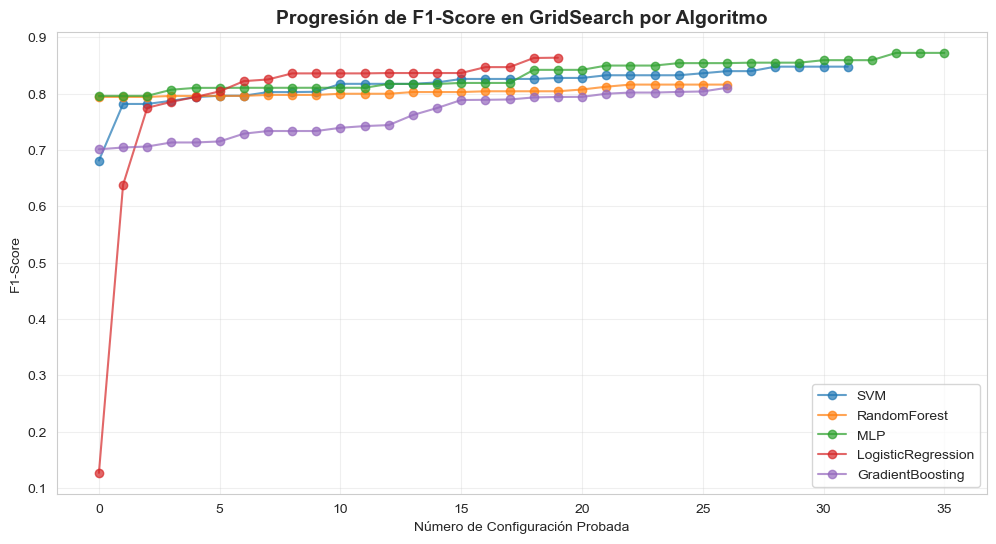

In [32]:
# ANÁLISIS 3: EVOLUCIÓN DE F1-SCORE POR ALGORITMO

plt.figure(figsize=(12, 6))

for algoritmo in df_grid['Algoritmo'].unique():
    df_algo = df_grid[df_grid['Algoritmo'] == algoritmo].sort_values('mean_test_f1')
    plt.plot(range(len(df_algo)), df_algo['mean_test_f1'], marker='o', alpha=0.7, label=algoritmo)

plt.title('Progresión de F1-Score en GridSearch por Algoritmo', fontsize=14, fontweight='bold')
plt.xlabel('Número de Configuración Probada')
plt.ylabel('F1-Score')
plt.legend()
plt.grid(alpha=0.3)
# guardar_grafica("evolucion_gridsearch.png")
plt.show()

---
### 4. Análisis de sensibilidad: impacto de los hiperparámetros

/var/folders/47/s5w64yxd357csjs44m5bkn1w0000gn/T/ipykernel_10787/2530457685.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


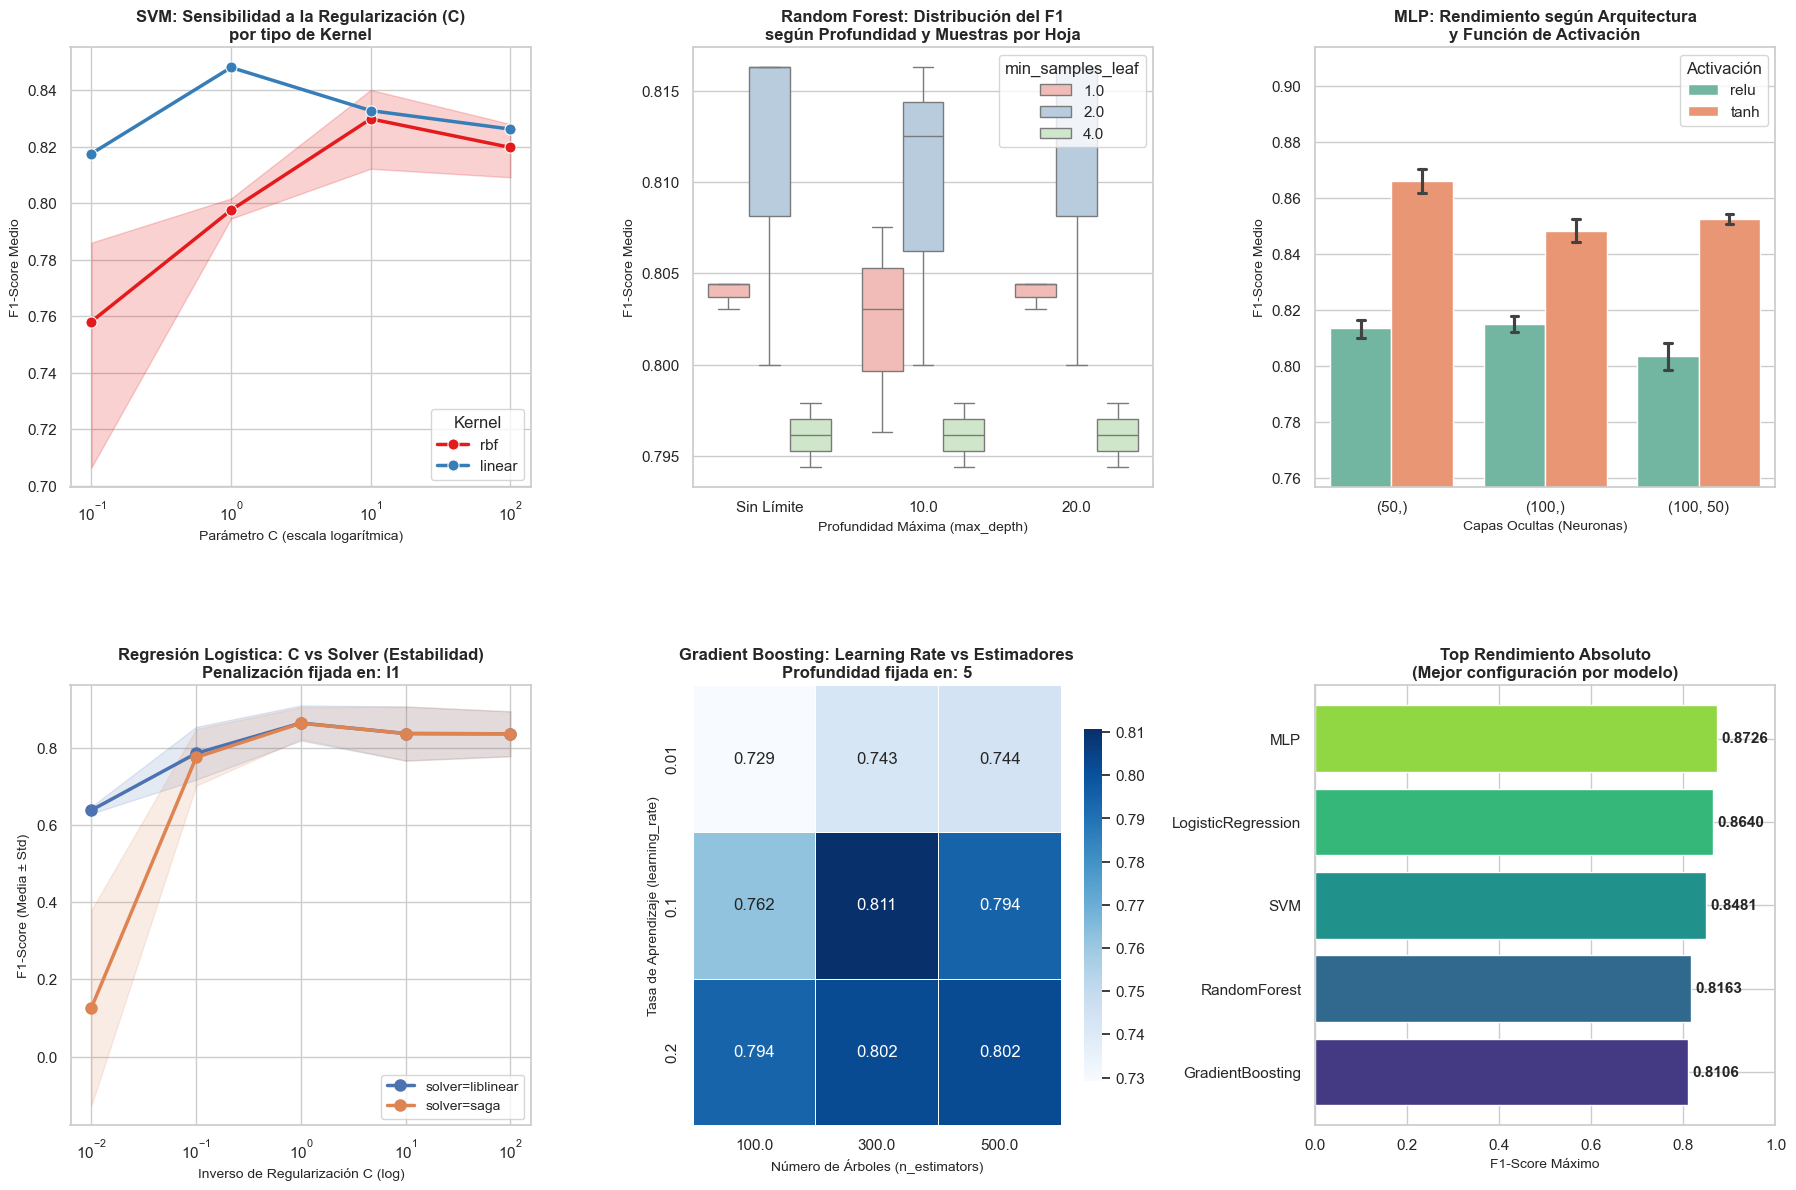

In [ ]:
fig = plt.figure(figsize=(22, 14))
# Layout: 2 filas × 3 columnas
gs = fig.add_gridspec(2, 3, hspace=0.45, wspace=0.35)

sns.set_theme(style="whitegrid")

# ── 1. SVM: Lineplot continuo (Impacto de C según el Kernel) ─────────────────
# Ideal para ver tendencias con ejes logarítmicos
ax1 = fig.add_subplot(gs[0, 0])
df_svm = df_grid[df_grid['Algoritmo'] == 'SVM'].copy()
df_svm['param_C'] = pd.to_numeric(df_svm['param_C'])
sns.lineplot(data=df_svm, x='param_C', y='mean_test_f1', hue='param_kernel', 
             marker='o', markersize=8, linewidth=2.5, palette='Set1', ax=ax1)
ax1.set_xscale('log')
ax1.set_title('SVM: Sensibilidad a la Regularización (C)\npor tipo de Kernel', fontweight='bold', fontsize=12)
ax1.set_xlabel('Parámetro C (escala logarítmica)', fontsize=10)
ax1.set_ylabel('F1-Score Medio', fontsize=10)
ax1.legend(title='Kernel')

# ── 2. Random Forest: Boxplot (Distribución y estabilidad del rendimiento) ────
# Ideal para ver cómo fluctúa el modelo al variar los estimadores
ax2 = fig.add_subplot(gs[0, 1])
df_rf = df_grid[df_grid['Algoritmo'] == 'RandomForest'].copy()
df_rf['param_max_depth'] = df_rf['param_max_depth'].fillna('Sin Límite').astype(str)
sns.boxplot(data=df_rf, x='param_max_depth', y='mean_test_f1', hue='param_min_samples_leaf', 
            palette='Pastel1', ax=ax2)
ax2.set_title('Random Forest: Distribución del F1\nsegún Profundidad y Muestras por Hoja', fontweight='bold', fontsize=12)
ax2.set_xlabel('Profundidad Máxima (max_depth)', fontsize=10)
ax2.set_ylabel('F1-Score Medio', fontsize=10)
ax2.legend(title='min_samples_leaf')

# ── 3. MLP: Barplot (Impacto de la topología y activación) ────────────────────
# Ideal para hiperparámetros puramente categóricos como las tuplas de arquitectura
ax3 = fig.add_subplot(gs[0, 2])
df_mlp = df_grid[df_grid['Algoritmo'] == 'MLP'].copy()
# Convertimos la tupla a string para que seaborn la lea bien
df_mlp['param_hidden_layer_sizes'] = df_mlp['param_hidden_layer_sizes'].astype(str)
sns.barplot(data=df_mlp, x='param_hidden_layer_sizes', y='mean_test_f1', hue='param_activation', 
            palette='Set2', capsize=.1, ax=ax3)
# Ajustamos el límite inferior para que las diferencias sean visibles (zoom in)
y_min_mlp = df_mlp['mean_test_f1'].min() * 0.95
ax3.set_ylim(bottom=y_min_mlp)
ax3.set_title('MLP: Rendimiento según Arquitectura\ny Función de Activación', fontweight='bold', fontsize=12)
ax3.set_xlabel('Capas Ocultas (Neuronas)', fontsize=10)
ax3.set_ylabel('F1-Score Medio', fontsize=10)
ax3.legend(title='Activación')

# ── 4. Regresión Logística: Curvas con área de desviación estándar ────────────
# Muestra la varianza del CV (tu idea original, limpiada y optimizada)
ax4 = fig.add_subplot(gs[1, 0])
df_lr = df_grid[df_grid['Algoritmo'] == 'LogisticRegression'].copy()
best_pen = df_lr.sort_values('mean_test_f1', ascending=False).iloc[0]['param_penalty']
df_lr_sub = df_lr[df_lr['param_penalty'] == best_pen].copy()
df_lr_sub['param_C'] = pd.to_numeric(df_lr_sub['param_C'])

for solver in df_lr_sub['param_solver'].unique():
    sub = df_lr_sub[df_lr_sub['param_solver'] == solver].sort_values('param_C')
    # Filtramos NaNs por combinaciones incompatibles solver-penalty
    sub = sub.dropna(subset=['mean_test_f1']) 
    if not sub.empty:
        line, = ax4.plot(sub['param_C'], sub['mean_test_f1'], 'o-', linewidth=2.5, markersize=8, label=f'solver={solver}')
        ax4.fill_between(sub['param_C'], 
                         sub['mean_test_f1'] - sub['std_test_f1'], 
                         sub['mean_test_f1'] + sub['std_test_f1'], 
                         alpha=0.15, color=line.get_color())

ax4.set_xscale('log')
ax4.set_title(f'Regresión Logística: C vs Solver (Estabilidad)\nPenalización fijada en: {best_pen}', fontweight='bold', fontsize=12)
ax4.set_xlabel('Inverso de Regularización C (log)', fontsize=10)
ax4.set_ylabel('F1-Score (Media ± Std)', fontsize=10)
ax4.legend(fontsize=10)

# ── 5. Gradient Boosting: Heatmap (Trade-off clásico) ─────────────────────────
# La mejor forma de ver la relación entre la tasa de aprendizaje y el nº de árboles
ax5 = fig.add_subplot(gs[1, 1])
df_gb = df_grid[df_grid['Algoritmo'] == 'GradientBoosting'].copy()
best_depth_gb = int(df_gb.sort_values('mean_test_f1', ascending=False).iloc[0]['param_max_depth'])
# Filtramos por la mejor profundidad
df_gb_sub = df_gb[df_gb['param_max_depth'] == best_depth_gb]
pivot_gb = df_gb_sub.pivot_table(index='param_learning_rate', columns='param_n_estimators', values='mean_test_f1')

sns.heatmap(pivot_gb, annot=True, fmt='.3f', cmap='Blues', ax=ax5, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax5.set_title(f'Gradient Boosting: Learning Rate vs Estimadores\nProfundidad fijada en: {best_depth_gb}', fontweight='bold', fontsize=12)
ax5.set_xlabel('Número de Árboles (n_estimators)', fontsize=10)
ax5.set_ylabel('Tasa de Aprendizaje (learning_rate)', fontsize=10)

# ── 6. Celda resumen: Gráfico de Barras Horizontales ──────────────────────────
# Más moderno y visual que una tabla insertada en matplotlib
ax6 = fig.add_subplot(gs[1, 2])
best_scores = df_grid.groupby('Algoritmo')['mean_test_f1'].max().sort_values(ascending=True)

bars = ax6.barh(best_scores.index, best_scores.values, color=sns.color_palette("viridis", len(best_scores)))
ax6.set_title('Top Rendimiento Absoluto\n(Mejor configuración por modelo)', fontweight='bold', fontsize=12)
ax6.set_xlabel('F1-Score Máximo', fontsize=10)
ax6.set_xlim(0, 1.0) # Ajustado de 0 a 1 porque F1 es un porcentaje

# Añadir las etiquetas de texto al final de cada barra
for bar in bars:
    width = bar.get_width()
    ax6.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}', 
             va='center', ha='left', fontsize=11, fontweight='bold')

plt.tight_layout()
# plt.savefig('sensibilidad_hiperparametros.pdf', bbox_inches='tight') # Formato PDF ideal para TFGs en LaTeX
plt.show()

---
### 5. Evaluación detallada del modelo ganador

In [16]:
# Instanciar el modelo ganador con hiperparámetros óptimos
# (Sustituir por el modelo/parámetros que salgan ganadores del GridSearch)
modelo_ganador_nombre = df_final.iloc[0]['Algoritmo']
print(f"Modelo ganador: {modelo_ganador_nombre} · F1={df_final.iloc[0]['f1']:.4f}")

# Mapa de instanciación con parámetros óptimos leídos del GridSearch
best_row = df_grid[df_grid['Algoritmo'] == modelo_ganador_nombre].sort_values('mean_test_f1', ascending=False).iloc[0]
best_params = {k.replace('param_', ''): v for k, v in best_row.items()
               if k.startswith('param_') and pd.notnull(v)}

# Convertir tipos para sklearn
for k, v in best_params.items():
    try:
        best_params[k] = int(v) if float(v) == int(float(v)) else float(v)
    except (ValueError, TypeError):
        pass  # strings como 'rbf', 'tanh' se dejan como están

print(f"Configuración óptima: {best_params}")

Modelo ganador: MLP · F1=0.8726
Configuración óptima: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': '(50,)', 'learning_rate_init': 0.001}


In [ ]:
# Predicciones out-of-fold
# Se construye manualmente el modelo ganador para tener control total
# IMPORTANTE: ajustar si el ganador cambia al ejecutar el GridSearch
modelo_final = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation='tanh',
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=42
)

y_pred   = cross_val_predict(modelo_final, X_proc, y_opt, cv=skf)
y_probas = cross_val_predict(modelo_final, X_proc, y_opt, cv=skf, method='predict_proba')
y_score  = y_probas[:, 1]   # probabilidad de clase TEA (label=2)

# Reporte textual
print("REPORTE DE CLASIFICACIÓN (predicciones out-of-fold, 5-fold CV)")
print("=" * 60)
print(classification_report(y_opt, y_pred, target_names=['Control', 'TEA']), zero_division=0)

REPORTE DE CLASIFICACIÓN (predicciones out-of-fold, 5-fold CV)
              precision    recall  f1-score   support

     Control       0.88      0.87      0.87        98
         TEA       0.88      0.89      0.89       111

    accuracy                           0.88       209
   macro avg       0.88      0.88      0.88       209
weighted avg       0.88      0.88      0.88       209



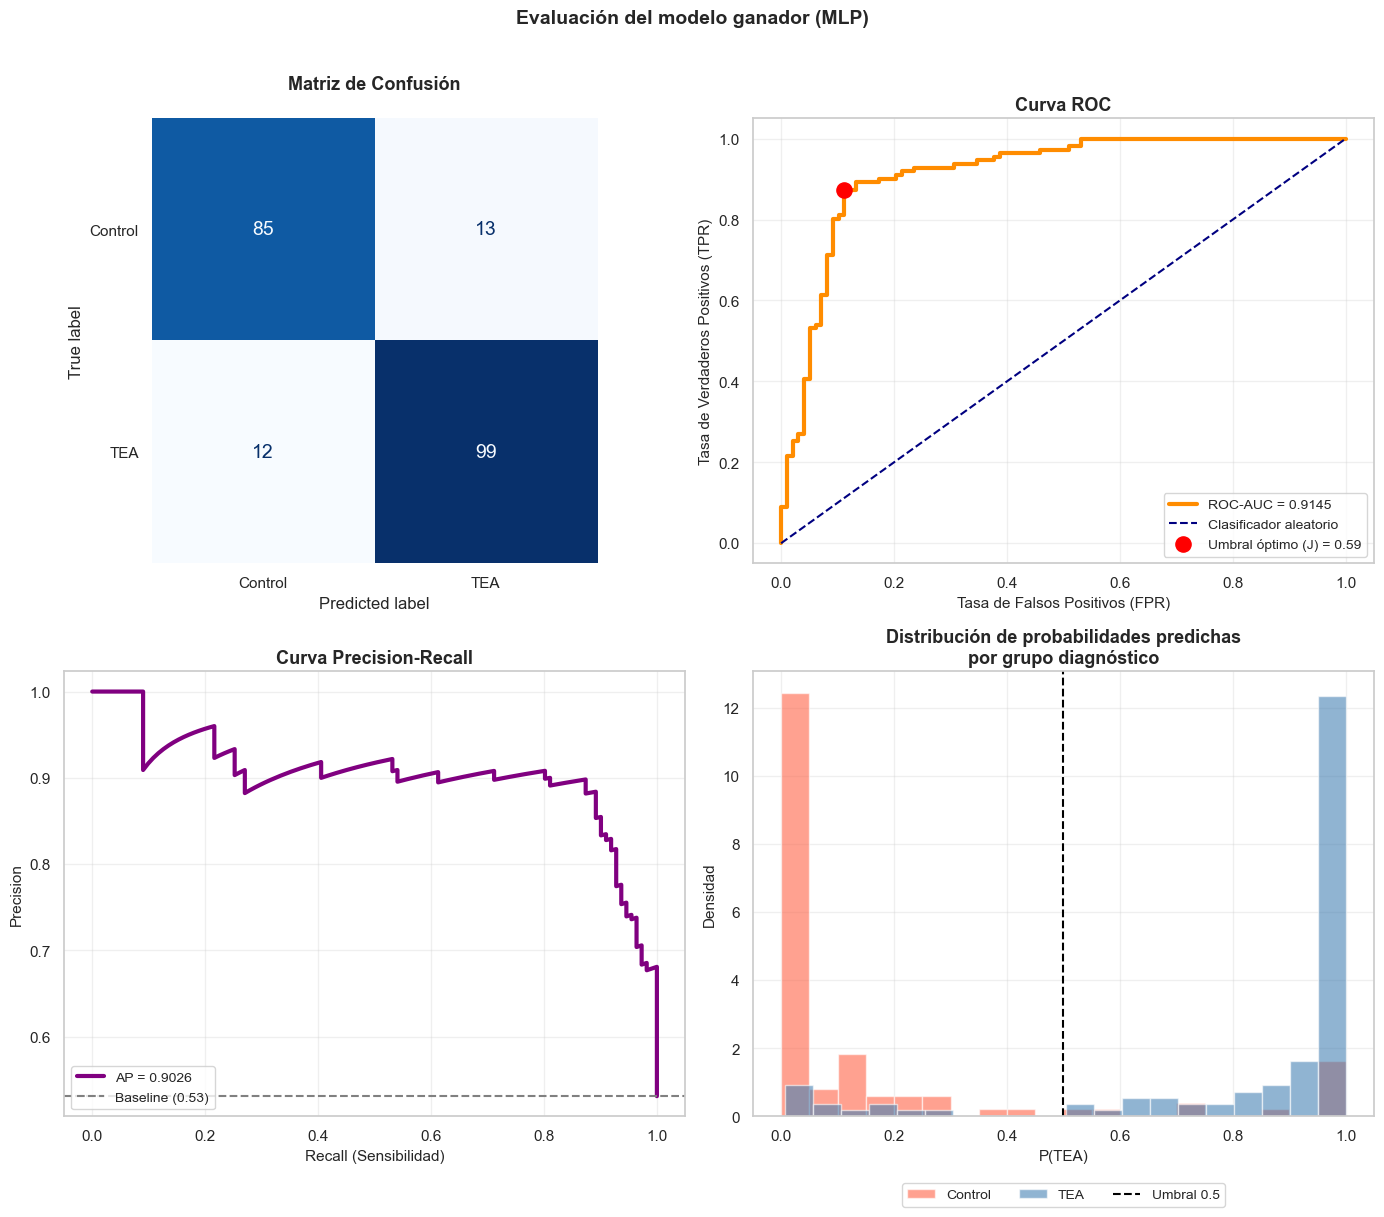

In [37]:
PALETA_DIAG = {'Control': 'tomato', 'TEA': 'steelblue'}
PALETA_DIAG_NUM = {1.0: 'tomato', 2.0: 'steelblue'}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# A: Matriz de confusión (panel superior izquierdo)
ax_cm = axes[0, 0]
ConfusionMatrixDisplay.from_predictions(
    y_opt, y_pred,
    display_labels=['Control', 'TEA'],
    cmap='Blues',
    colorbar=False,
    ax=ax_cm
)
ax_cm.set_title('Matriz de Confusión\n', fontweight='bold', fontsize=13)
ax_cm.grid(False)
for spine in ax_cm.spines.values():
    spine.set_visible(False)
for text in ax_cm.texts:
    text.set_fontsize(14)

# B: Curva ROC (panel superior derecho)
ax_roc = axes[0, 1]
fpr, tpr, thresholds = roc_curve(y_opt, y_score, pos_label=2)
roc_auc_val = auc(fpr, tpr)

ax_roc.plot(fpr, tpr, color='darkorange', lw=3,
            label=f'ROC-AUC = {roc_auc_val:.4f}')
ax_roc.plot([0, 1], [0, 1], color='navy', linestyle='--', lw=1.5, label='Clasificador aleatorio')
j_scores = tpr - fpr
best_thresh_idx = np.argmax(j_scores)
ax_roc.scatter(fpr[best_thresh_idx], tpr[best_thresh_idx], s=120, color='red', zorder=5,
               label=f"Umbral óptimo (J) = {thresholds[best_thresh_idx]:.2f}")
ax_roc.set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=11)
ax_roc.set_ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=11)
ax_roc.set_title('Curva ROC', fontweight='bold', fontsize=13)
ax_roc.legend(loc='lower right', fontsize=10)
ax_roc.grid(alpha=0.3)

# C: Curva Precision-Recall (panel inferior izquierdo)
ax_pr = axes[1, 0]
precision_vals, recall_vals, _ = precision_recall_curve(y_opt, y_score, pos_label=2)
ap = average_precision_score(y_opt, y_score, pos_label=2)

ax_pr.plot(recall_vals, precision_vals, color='purple', lw=3, label=f'AP = {ap:.4f}')
baseline_pr = (y_opt == 2).mean()
ax_pr.axhline(y=baseline_pr, color='gray', linestyle='--', lw=1.5,
              label=f'Baseline ({baseline_pr:.2f})')
ax_pr.set_xlabel('Recall (Sensibilidad)', fontsize=11)
ax_pr.set_ylabel('Precision', fontsize=11)
ax_pr.set_title('Curva Precision-Recall', fontweight='bold', fontsize=13)
ax_pr.legend(loc='lower left', fontsize=10)
ax_pr.grid(alpha=0.3)

# D: Distribución de probabilidades predichas por clase
ax_dist = axes[1, 1]
mask_control = (y_opt.values == 1)
mask_tea     = (y_opt.values == 2)

ax_dist.hist(y_score[mask_control], bins=20, alpha=0.6,
             color=PALETA_DIAG['Control'],
             label='Control', edgecolor='white', density=True)
ax_dist.hist(y_score[mask_tea], bins=20, alpha=0.6,
             color=PALETA_DIAG['TEA'],
             label='TEA', edgecolor='white', density=True)
ax_dist.axvline(x=0.5, color='black', linestyle='--', lw=1.5, label='Umbral 0.5')
ax_dist.set_xlabel('P(TEA)', fontsize=11)
ax_dist.set_ylabel('Densidad', fontsize=11)
ax_dist.set_title('Distribución de probabilidades predichas\npor grupo diagnóstico', fontweight='bold', fontsize=13)
ax_dist.legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, borderaxespad=0.)
ax_dist.grid(alpha=0.3)

plt.suptitle(
    f'Evaluación del modelo ganador ({modelo_ganador_nombre})',
    fontsize=14, fontweight='bold', y=1.01
)
plt.tight_layout()
# guardar_grafica('evaluacion_modelo_ganador.png', fig)
plt.show()

---
### 6. Ganancia de la optimización: modelo ganador vs. configuración por defecto

In [ ]:
# Valores por defecto de scikit-learn para el modelo ganador (MLP)
# Ajustar si el ganador cambia al ejecutar

modelo_default = MLPClassifier(random_state=42, max_iter=1000)

res_default  = cross_validate(modelo_default, X_proc, y_opt, cv=skf, scoring=METRICAS_DICT)
res_optimo   = cross_validate(modelo_final,   X_proc, y_opt, cv=skf, scoring=METRICAS_DICT)

comparativa = pd.DataFrame({
    'Métrica': METRICAS,
    'Por defecto':  [res_default[f'test_{m}'].mean() for m in METRICAS],
    'Optimizado':   [res_optimo[f'test_{m}'].mean()  for m in METRICAS],
})
comparativa['Ganancia'] = comparativa['Optimizado'] - comparativa['Por defecto']
comparativa = comparativa.set_index('Métrica')

print(f"Comparativa {modelo_ganador_nombre}: por defecto vs. hiperparámetros optimizados")
display(
    comparativa.style
    .background_gradient(cmap='RdYlGn', subset=['Ganancia'])
    .format('{:.4f}')
)

Comparativa MLP: por defecto vs. hiperparámetros optimizados


,Por defecto,Optimizado,Ganancia
Métrica,,,
accuracy,0.8326,0.8805,0.0479
precision,0.8529,0.8895,0.0366
recall,0.8068,0.8674,0.0605
f1,0.8192,0.8726,0.0534
roc_auc,0.9129,0.9204,0.0075
